In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import torch
from tiny_gpt import TinyGPT, train, generate_text, uniform_random_loss, evaluate_lm
from scripts.prepare_data import gather_data, format_data
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, "| CUDA:", torch.cuda.is_available())

2.11.0+cu128 | CUDA: True


In [2]:
text = gather_data()

=== Wikipedia (23 pages) ===
Fetched: https://en.wikipedia.org/wiki/Dog
  Paragraphs: 80
  Failed https://en.wikipedia.org/wiki/Dog_behavior: 403 Client Error: Too many requests. Please respect our robot policy https://w.wiki/4wJS. (dd12474) for url: https://en.wikipedia.org/wiki/Dog_behavior
  Failed https://en.wikipedia.org/wiki/Dog_training: 403 Client Error: Too many requests. Please respect our robot policy https://w.wiki/4wJS. (dd12474) for url: https://en.wikipedia.org/wiki/Dog_training
Fetched: https://en.wikipedia.org/wiki/Labrador_Retriever
  Paragraphs: 24
Fetched: https://en.wikipedia.org/wiki/Golden_Retriever
  Paragraphs: 22
Fetched: https://en.wikipedia.org/wiki/German_Shepherd
  Paragraphs: 48
  Failed https://en.wikipedia.org/wiki/Poodle: 403 Client Error: Too many requests. Please respect our robot policy https://w.wiki/4wJS. (dd12474) for url: https://en.wikipedia.org/wiki/Poodle
  Failed https://en.wikipedia.org/wiki/Bulldog: 403 Client Error: Too many requests. Ple

In [3]:
seq_len = 64
input_ids, target_ids, vocab, stoi, itos = format_data(text, seq_len=seq_len)

Vocab size : 10,728
Sequences  : 530,138  (seq_len=64)
<unk> rate : 4.59%


In [4]:
input_ids  = input_ids.to(device)
target_ids = target_ids.to(device)

split_idx = int(0.9 * input_ids.size(0))
train_input_ids,  val_input_ids  = input_ids[:split_idx],  input_ids[split_idx:]
train_target_ids, val_target_ids = target_ids[:split_idx], target_ids[split_idx:]

print("Train:", train_input_ids.shape, "| Val:", val_input_ids.shape)

Train: torch.Size([477124, 64]) | Val: torch.Size([53014, 64])


In [5]:
model = TinyGPT(
    vocab_size=len(vocab),
    d_model=128,
    hidden_dim=1024,
    num_layers=4,
    max_len=seq_len,
    dropout=0.05
).to(device)


print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 2,692,864


In [6]:
uniform = uniform_random_loss(len(vocab))

print(f"Vocab size:            {len(vocab):,}")
print(f"Uniform random loss:   {uniform:.4f}   (knows nothing)")


Vocab size:            10,728
Uniform random loss:   9.2806   (knows nothing)


In [7]:
for name, t in [("train_input", train_input_ids), ("train_target", train_target_ids),
                ("val_input", val_input_ids), ("val_target", val_target_ids)]:
    print(f"{name}: {t.shape}  {t.element_size() * t.numel() / 1e6:.1f} MB")

# model memory
param_mb = sum(p.element_size() * p.numel() for p in model.parameters()) / 1e6
print(f"\nModel params: {param_mb:.1f} MB")
print(f"AdamW buffers (est): {param_mb * 2:.1f} MB")

train_input: torch.Size([477124, 64])  244.3 MB
train_target: torch.Size([477124, 64])  244.3 MB
val_input: torch.Size([53014, 64])  27.1 MB
val_target: torch.Size([53014, 64])  27.1 MB

Model params: 10.8 MB
AdamW buffers (est): 21.5 MB



Epoch 01/5
-----------------------------------------------------------------
  batch   1000/29821 | loss 8.7087  acc 0.0447 | lr 2.01e-05
  batch   2000/29821 | loss 6.7892  acc 0.0622 | lr 4.02e-05
  batch   3000/29821 | loss 6.2711  acc 0.0631 | lr 6.04e-05
  batch   4000/29821 | loss 6.2150  acc 0.0762 | lr 8.05e-05
  batch   5000/29821 | loss 5.9850  acc 0.1104 | lr 1.01e-04
  batch   6000/29821 | loss 5.7738  acc 0.1260 | lr 1.21e-04
  batch   7000/29821 | loss 5.6486  acc 0.1324 | lr 1.41e-04
  batch   8000/29821 | loss 5.5066  acc 0.1435 | lr 1.61e-04
  batch   9000/29821 | loss 5.3812  acc 0.1534 | lr 1.81e-04
  batch  10000/29821 | loss 5.2729  acc 0.1651 | lr 2.01e-04
  batch  11000/29821 | loss 5.1771  acc 0.1730 | lr 2.21e-04
  batch  12000/29821 | loss 5.0964  acc 0.1814 | lr 2.41e-04
  batch  13000/29821 | loss 5.0321  acc 0.1843 | lr 2.62e-04
  batch  14000/29821 | loss 4.9624  acc 0.1917 | lr 2.82e-04
  batch  15000/29821 | loss 4.9164  acc 0.1940 | lr 3.00e-04
  batch

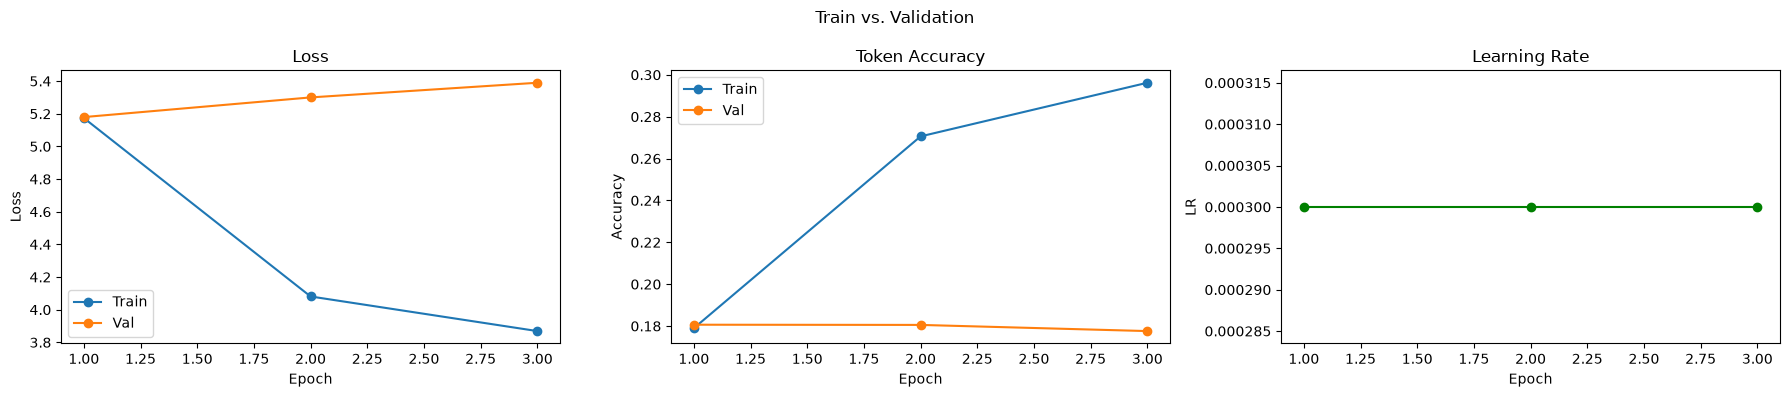

In [8]:
train_losses, val_losses, train_accs, val_accs = train(
    model,
    train_input_ids, train_target_ids,
    val_input_ids,   val_target_ids,
    num_epochs=5,
    batch_size=16,
    device=device,
    weight_decay=0.01,
    lr = 3e-4,
    log_every = 1000,
    ckpt_path="../checkpoints/best.pt",
)

In [9]:
checkpoint = torch.load("../checkpoints/best.pt")
model.load_state_dict(checkpoint["model_state"])

metrics = evaluate_lm(
    model,
    val_input_ids, val_target_ids,
    vocab,
    train_target_ids=train_target_ids,   # needed for the unigram baseline
    device=device,
)

LANGUAGE MODEL EVALUATION

Vocab size:              10,728

── Your model ──
Validation loss:         5.1797 nats
Validation perplexity:   177.6
Token accuracy:          18.06%  (next word exactly right)

── Baselines (what you're beating) ──
Uniform random loss:     9.2806  (perplexity 10,728)
  → knows nothing, picks any of 10,728 words equally
Unigram loss:            6.2556  (perplexity 521)
  → knows word frequencies, but ignores all context

── Interpretation ──
Your model effectively chooses between ~178 words per step,
instead of 10,728 (random) — it closed 44.2% of the
gap from random toward perfect prediction.

✓ It beats the unigram baseline by 1.08 nats —
  meaning it genuinely USES CONTEXT, not just word frequency.
